# Boston Housing：五種特徵選擇與線性迴歸

與 50 Startups 相同的五個方法：Exhaustive、Forward、Backward、RFECV、Lasso。

資料為明確標示 [Kaggle 競賽](https://www.kaggle.com/c/boston-housing) 來源的 [公開鏡像](https://gist.github.com/Abhinav-Mahapatra/b23f70e2d57ac182a25372b9bb8d4792)，333 筆有標籤資料、173 筆未標籤資料。鏡像 TSV 已等值轉成 CSV；未讀取測試答案。

先以 random_state=42 將有標籤資料切成 266 筆訓練、67 筆保留驗證；所有選擇與 alpha 調整只在訓練集 5-fold CV 進行。最後依訓練 CV 選預設方法，以全部 333 筆重 fit 選定設定並輸出提交檔。

medv 的單位是歷史美元千元；是區域自住房價中位數，不是單棟今日估價。原資料有 50 的目標上限，black 欄位是帶已知建構問題的歷史種族轉換指標。此分析保留原始 13 欄作課程方法重現，係數不解讀為因果或現代實務估價。

執行：將 Notebook、analysis.py、feature_selection.py、train.csv、test.csv 放在同一資料夾，安裝 requirements.txt，再 Run All。


## 1. 資料與固定切分

In [1]:
from pathlib import Path
import json, sys, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import sklearn, statsmodels.api as sm
from scipy import stats
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
BASE=Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
sys.path.insert(0,str(BASE))
from feature_selection import compare_selection_schemes, prepare_data, FEATURES, METHODS
RESULTS=BASE/'results'; RESULTS.mkdir(exist_ok=True)
train=pd.read_csv(BASE/'train.csv'); test=pd.read_csv(BASE/'test.csv')
assert train.shape==(333,15) and test.shape==(173,14)
assert not train.isna().any().any() and not test.isna().any().any()
assert train.ID.is_unique and test.ID.is_unique and set(train.ID).isdisjoint(test.ID)
X,y,tr,va=prepare_data(train)
print(f'Kaggle labeled: {len(train)}; unlabeled: {len(test)}; predictors: {len(FEATURES)}')
print(f'Internal training: {len(tr)}; held-out validation: {len(va)}; split seed=42')
print('MEDV is in historical USD 1,000; ID is excluded. All 13 original predictors retained for coursework.')



Kaggle labeled: 333; unlabeled: 173; predictors: 13
Internal training: 266; held-out validation: 67; split seed=42
MEDV is in historical USD 1,000; ID is excluded. All 13 original predictors retained for coursework.


## 2. 五種特徵選擇（僅以 266 筆訓練與共用 5-fold CV 選擇）

In [2]:
# Exhaustive: 8191 subsets. Forward/Backward: greedy CV paths.
# RFECV: fold-specific coefficient elimination. Lasso: alpha grid 1e-4..10.
comparison=compare_selection_schemes(train,RESULTS)
details=json.loads((RESULTS/'selection_models.json').read_text())
protocol=json.loads((RESULTS/'selection_protocol.json').read_text())
chosen_method=str(comparison.iloc[0]['method'])  # sorted by CV RMSE, never validation RMSE
print(comparison[['method','n_features','features','cv_rmse','test_rmse','test_r_squared']].round(5).to_string(index=False))
print('Default submission method selected by TRAINING CV:',chosen_method)



Exhaustive finished: 8191 subsets
    method  n_features                                                                              features  cv_rmse  test_rmse  test_r_squared
  Backward          10                      zn | chas | nox | rm | dis | rad | tax | ptratio | black | lstat  5.10329    4.79195         0.74485
Exhaustive          10                      zn | chas | nox | rm | dis | rad | tax | ptratio | black | lstat  5.10329    4.79195         0.74485
   Forward          10                      zn | chas | nox | rm | dis | rad | tax | ptratio | black | lstat  5.10329    4.79195         0.74485
     Lasso          13 crim | zn | indus | chas | nox | rm | age | dis | rad | tax | ptratio | black | lstat  5.15387    4.84114         0.73959
     RFECV          13 crim | zn | indus | chas | nox | rm | age | dis | rad | tax | ptratio | black | lstat  5.15391    4.84631         0.73903
Default submission method selected by TRAINING CV: Backward


## 3. 平均值與全特徵基準、OLS 診斷

In [3]:
def metrics(actual,pred):
    return {'RMSE':float(np.sqrt(mean_squared_error(actual,pred))),
            'MAE':float(mean_absolute_error(actual,pred)), 'R2':float(r2_score(actual,pred))}
baseline=[]
mean_pred=np.full(len(va),float(y.iloc[tr].mean()))
baseline.append({'model':'Mean baseline',**metrics(y.iloc[va],mean_pred)})
full=Pipeline([('scale',StandardScaler()),('model',LinearRegression())]).fit(X.iloc[tr],y.iloc[tr])
baseline.append({'model':'Full OLS (13 features)',**metrics(y.iloc[va],full.predict(X.iloc[va]))})
pd.DataFrame(baseline).to_csv(RESULTS/'baseline_metrics.csv',index=False)
scale=full.named_steps['scale']; design=sm.add_constant(pd.DataFrame(scale.transform(X.iloc[tr]),columns=FEATURES),has_constant='add')
ols=sm.OLS(y.iloc[tr].to_numpy(),design).fit(cov_type='HC3')
ci=ols.conf_int()
coefficients=pd.DataFrame({'feature':ols.params.index,'coefficient':ols.params.values,'CI95_low':ci.iloc[:,0].values,'CI95_high':ci.iloc[:,1].values,'p_value':ols.pvalues.values})
coefficients.to_csv(RESULTS/'ols_coefficients.csv',index=False)
(RESULTS/'ols_summary.txt').write_text(ols.summary().as_text())
vif=pd.DataFrame({'feature':FEATURES,'VIF':[variance_inflation_factor(design.to_numpy(),i+1) for i in range(len(FEATURES))]}).sort_values('VIF',ascending=False)
vif.to_csv(RESULTS/'vif.csv',index=False)
resid=y.iloc[va].to_numpy()-full.predict(X.iloc[va])
print(pd.DataFrame(baseline).round(4).to_string(index=False))
print('Full OLS training adjusted R2:',ols.rsquared_adj)
print('BP p:',het_breuschpagan(ols.resid,design)[1], 'JB p:',stats.jarque_bera(ols.resid).pvalue)



                 model   RMSE    MAE      R2
         Mean baseline 9.4997 6.8879 -0.0027
Full OLS (13 features) 4.8463 3.6175  0.7390
Full OLS training adjusted R2: 0.7114765884891414
BP p: 0.006883581849268226 JB p: 9.079087884303534e-88


## 4. 以全部 333 筆重新擬合，產生 173 筆 Kaggle 提交預測

In [4]:
# Keep features/alpha chosen in section 2; never use validation outcomes to select a method.
submission_models={}; kaggle_predictions=[]
for method in METHODS:
    info=details[method]
    cols=FEATURES if method=='Lasso' else info['selected_features']
    reg=Lasso(alpha=info['alpha'],max_iter=100000,tol=1e-8) if method=='Lasso' else LinearRegression()
    pipe=Pipeline([('scale',StandardScaler()),('model',reg)]).fit(X[cols],y)
    scaler=pipe.named_steps['scale']; fitted=pipe.named_steps['model']
    raw=fitted.coef_/scaler.scale_
    model={'raw_intercept':float(fitted.intercept_-np.dot(raw,scaler.mean_)),
           'raw_coefficients':dict(zip(cols,raw.tolist())), 'selected_features':info['selected_features'],
           'alpha':info['alpha'], 'trained_rows':333}
    submission_models[method]=model
    predictions=pipe.predict(test[cols])
    exported=np.array([model['raw_intercept']+sum(c*row[f] for f,c in model['raw_coefficients'].items()) for _,row in test.iterrows()])
    assert np.allclose(exported,predictions,atol=1e-9)
    submission=pd.DataFrame({'ID':test.ID,'medv':predictions})
    assert len(submission)==173 and np.isfinite(submission.medv).all()
    submission.to_csv(RESULTS/f'submission_{method.lower()}.csv',index=False)
    if method==chosen_method:submission.to_csv(BASE/'submission.csv',index=False)
    kaggle_predictions.extend({'method':method,'ID':int(i),'predicted_medv':float(p)} for i,p in zip(test.ID,predictions))
(RESULTS/'submission_models.json').write_text(json.dumps(submission_models,indent=2))
pd.DataFrame(kaggle_predictions).to_csv(RESULTS/'kaggle_predictions.csv',index=False)
print(f'Generated 5 submission files, each 173 rows; default submission.csv = {chosen_method}.')
print('No Kaggle test targets used; no leaderboard score claimed; no automatic competition submission.')



Generated 5 submission files, each 173 rows; default submission.csv = Backward.
No Kaggle test targets used; no leaderboard score claimed; no automatic competition submission.


## 5. 圖表、可重現摘要與網站資料

In [5]:
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.spines.top':False,'axes.spines.right':False,'figure.facecolor':'#f5f6f8','savefig.dpi':150})
fig,ax=plt.subplots(1,2,figsize=(12,4.5)); ordered=comparison.set_index('method').loc[METHODS]
ax[0].bar(METHODS,ordered.cv_rmse,yerr=ordered.cv_rmse_std,capsize=4,color='#168974')
ax[0].set(title='Training 5-fold CV RMSE (SD)',ylabel='RMSE (historical USD 1,000)')
ax[1].bar(METHODS,ordered.test_rmse,color='#367de9');ax[1].set(title='67-row held-out validation RMSE',ylabel='RMSE (historical USD 1,000)')
for a in ax:a.tick_params(axis='x',rotation=20)
fig.tight_layout();fig.savefig(RESULTS/'comparison.png');plt.close(fig)
fig,ax=plt.subplots(1,3,figsize=(14,4.2));pred=full.predict(X.iloc[va])
ax[0].scatter(y.iloc[va],pred,color='#168974',alpha=.7);ax[0].plot([0,55],[0,55],'--',color='#b88b4a');ax[0].set(title='Full OLS: actual vs predicted',xlabel='Actual medv',ylabel='Predicted medv')
ax[1].scatter(pred,resid,color='#367de9',alpha=.7);ax[1].axhline(0,color='#b88b4a',linestyle='--');ax[1].set(title='Full OLS: validation residuals',xlabel='Predicted medv',ylabel='Actual - predicted')
stats.probplot(resid,plot=ax[2]);ax[2].set_title('Validation residual Q-Q')
fig.tight_layout();fig.savefig(RESULTS/'diagnostics.png');plt.close(fig)
corr=train.drop(columns='ID').corr()
corr.to_csv(RESULTS/'correlation.csv')
fig,ax=plt.subplots(1,2,figsize=(11,4.3));ax[0].hist(train.medv,bins=23,color='#168974',edgecolor='white');ax[0].set(title='Labeled medv distribution',xlabel='Historical USD 1,000',ylabel='Observations')
ax[1].scatter(train.rm,train.medv,color='#367de9',alpha=.55,s=15);ax[1].set(title=f'Rooms vs medv (r={corr.loc["rm","medv"]:.3f})',xlabel='Average rooms',ylabel='medv (USD 1,000)')
fig.tight_layout();fig.savefig(RESULTS/'eda.png');plt.close(fig)
summary={'labeled_rows':333,'kaggle_test_rows':173,'train_rows':len(tr),'validation_rows':len(va),
         'features':FEATURES,'exhaustive_subsets':8191,'cv_folds':5,'seed':42,'chosen_method_by_cv':chosen_method,
         'target':'medv','target_unit':'historical USD 1,000','capped_target_count':int((train.medv==50).sum()),
         'ols_adjusted_r2':float(ols.rsquared_adj),'BP_p':float(het_breuschpagan(ols.resid,design)[1]),
         'JB_p':float(stats.jarque_bera(ols.resid).pvalue),
         'versions':{'numpy':np.__version__,'pandas':pd.__version__,'scikit-learn':sklearn.__version__,'statsmodels':sm.__version__,'matplotlib':matplotlib.__version__}}
(RESULTS/'summary.json').write_text(json.dumps(summary,indent=2))
def rec(path):return json.loads(pd.read_csv(path).to_json(orient='records',double_precision=14))
payload={'dataset':rec(BASE/'train.csv'),'kaggle_test':rec(BASE/'test.csv'),
         'selection':rec(RESULTS/'selection_comparison.csv'),'curves':rec(RESULTS/'selection_feature_curves.csv'),
         'history':rec(RESULTS/'selection_cv_history.csv'),'predictions':rec(RESULTS/'selection_predictions.csv'),
         'curve_predictions':rec(RESULTS/'selection_curve_predictions.csv'),
         'models':details,'submission_models':submission_models,'protocol':protocol,
         'summary':summary,'vif':rec(RESULTS/'vif.csv'),'coefficients':rec(RESULTS/'ols_coefficients.csv'),
         'baseline':baseline,'source':(BASE/'analysis.py').read_text(),'selection_source':(BASE/'feature_selection.py').read_text(),
         'kaggle_predictions':kaggle_predictions,'provenance':json.loads((BASE/'provenance.json').read_text())}
(BASE/'web_data.json').write_text(json.dumps(payload,ensure_ascii=False,allow_nan=False))
print('Completed analysis, feature-count curves, diagnostics and browser model exports.')


Completed analysis, feature-count curves, diagnostics and browser model exports.


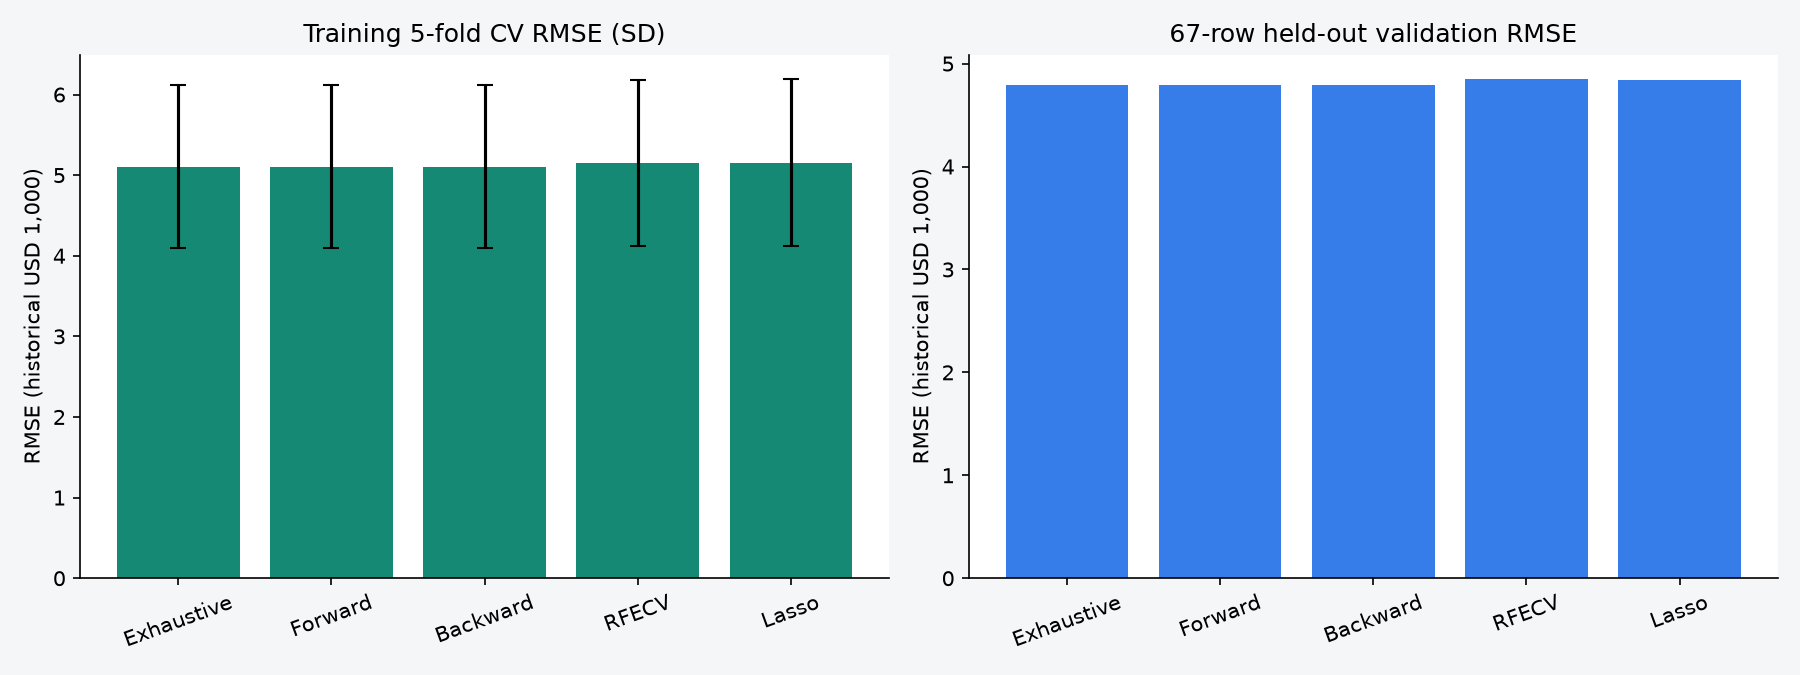

In [11]:
from IPython.display import display, Image
display(Image(filename=str(RESULTS / 'comparison.png')))

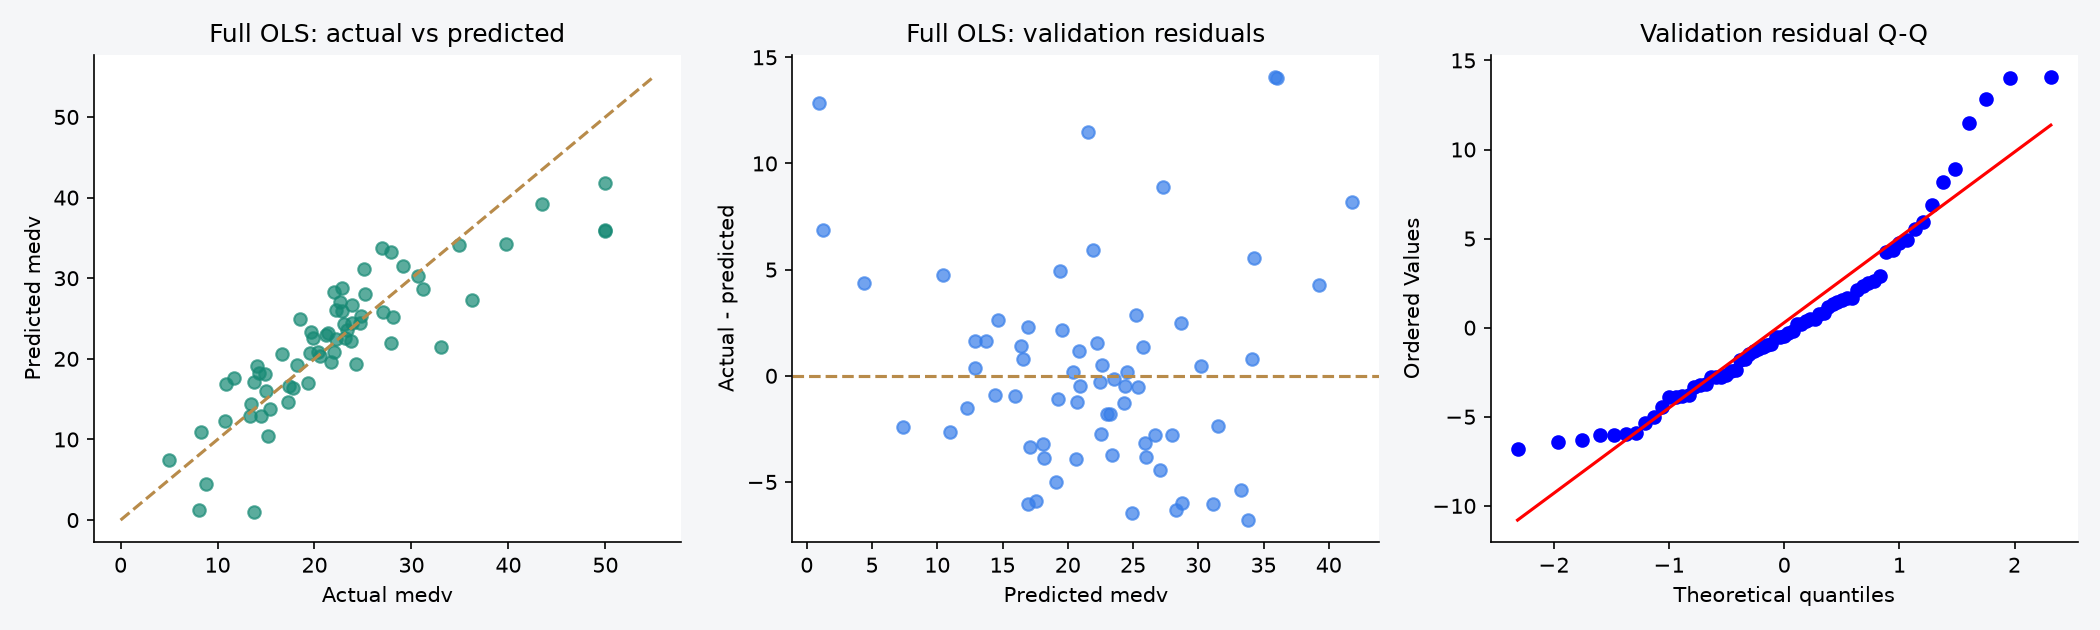

In [12]:
from IPython.display import display, Image
display(Image(filename=str(RESULTS / 'diagnostics.png')))

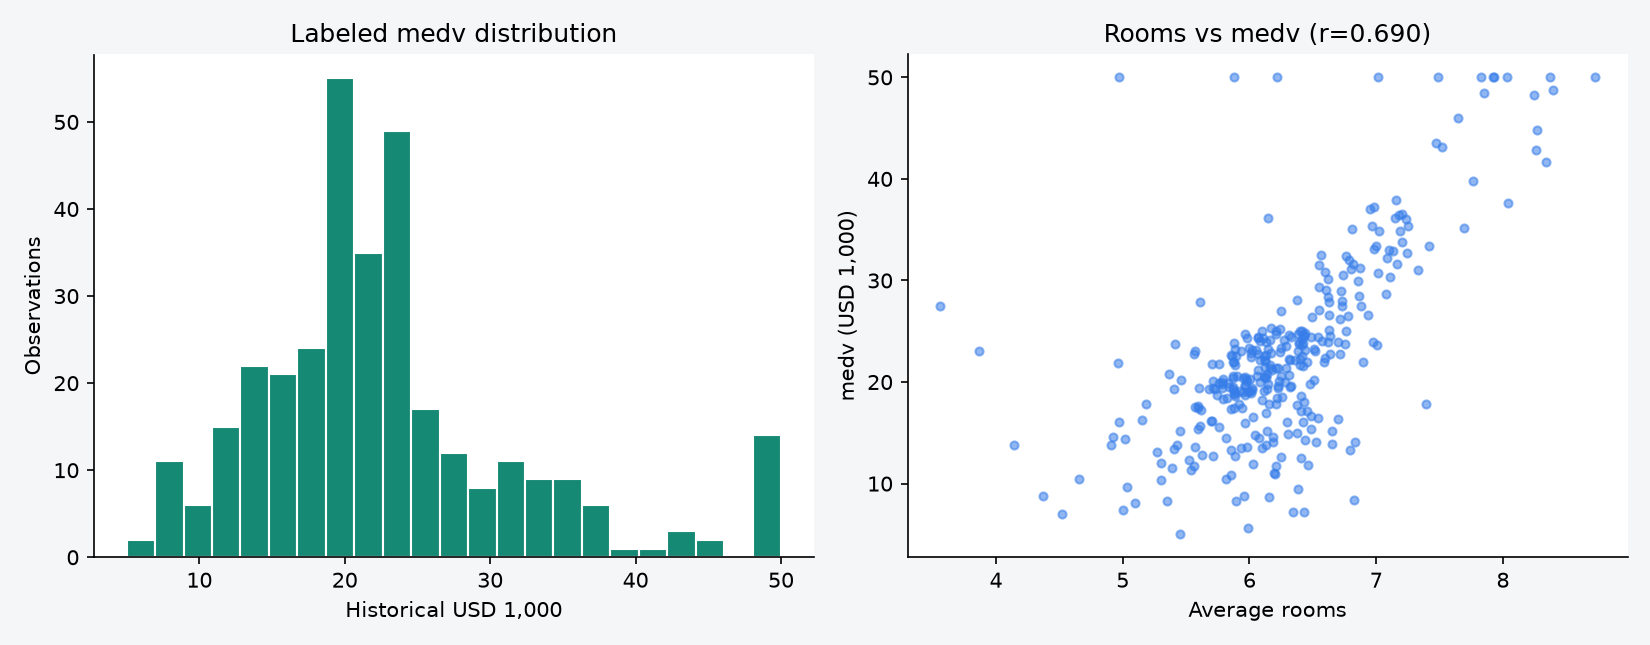

In [13]:
from IPython.display import display, Image
display(Image(filename=str(RESULTS / 'eda.png')))